# Imports 

In [57]:
import contextily as ctx
import os
import sys
from datetime import datetime
from glob import glob
import urllib
from pathlib import Path

import cdsapi
import geopandas as gpd
import hvplot.xarray
import imageio
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import hvplot.pandas
import rasterio
import pandas as pd
import xarray as xr
import openeo
from openeo.api.process import Parameter
from shapely.geometry import Point, box
from pyproj import Transformer
import rioxarray
from pystac_client import Client
import bokeh
from tqdm.notebook import tqdm
from IPython.display import Image, display
from matplotlib.animation import PillowWriter


# AOI and POI

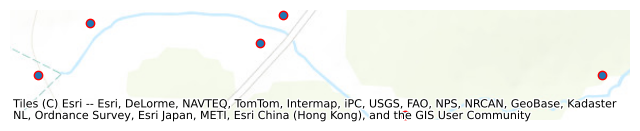

In [58]:
# site_name = 'leze' # ['2022-01-01', '2022-01-31'] 
# site_name = 'pinios' # ['2023-08-01','2023-12-01']
site_name = 'milton' # ['2024-11-10', '2024-12-10']

## Period of interest
poi = ['2024-11-20', '2024-11-30']
startYear = int(poi[0][:4])
endYear = int(poi[1][:4])

if site_name == 'pinios':
    aois = gpd.read_file('/Users/vm/Desktop/dir.tmp/spongeworks/data/Pinios/gis_data/s7_lake_karla/s7_lake_karla.shp')
if site_name == 'vecht':
    aois1 = gpd.read_file('/Users/vm/Desktop/dir.tmp/spongeworks/data/Vecht/vecht_top_aos 1.gpkg')
    aois2 = gpd.read_file('/Users/vm/Desktop/dir.tmp/spongeworks/data/Vecht/vecht_top_sites.gpkg')
    aois = gpd.GeoDataFrame(pd.concat([aois1, aois2], ignore_index=True), crs=aois1.crs)
if site_name == 'leze':    
    aoi1 = gpd.read_file('/Users/vm/Desktop/dir.tmp/spongeworks/data/Leze/hedges_aos.gpkg')
    aoi2 = gpd.read_file('/Users/vm/Desktop/dir.tmp/spongeworks/data/Leze/eval_sites_aos.gpkg')
    aois = gpd.GeoDataFrame(pd.concat([aoi1, aoi2], ignore_index=True), crs=aoi1.crs)
if site_name == 'milton':    
    # aoi1 = gpd.read_file('/Users/vm/Desktop/dir.tmp/spongeworks/data/Milton/vectors/milton_rivers.geojson')
    # aoi2 = gpd.read_file('/Users/vm/Desktop/dir.tmp/spongeworks/data/Milton/vectors/milton_points.geojson')
    # aois = gpd.GeoDataFrame(pd.concat([aoi1, aoi2], ignore_index=True), crs=aoi1.crs)
    aois = gpd.read_file('/Users/vm/Desktop/dir.tmp/spongeworks/data/Milton/vectors/milton_points.geojson')[3:]

aois_web = aois.to_crs(epsg=3857)
ax = aois_web.plot(
    figsize=(8, 8),
    # facecolor="none",
    edgecolor="red",
    linewidth=1,
)

ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTopoMap)
ax.set_axis_off()
plt.show()

# Build bbox from AOIs extent with +2 km margin on each side
aois_metric = aois.to_crs(aois.estimate_utm_crs())
minx, miny, maxx, maxy = aois_metric.total_bounds

bbox_radius = 1000  # 100 meters margin

bbox_metric = box(minx - bbox_radius, miny - bbox_radius, maxx + bbox_radius, maxy + bbox_radius)
bbox_gdf = gpd.GeoDataFrame(geometry=[bbox_metric], crs=aois_metric.crs).to_crs("4326")
bbox = bbox_gdf.geometry.iloc[0]

# bbox_web = bbox_gdf.to_crs(epsg=3857)
# bbox_web.boundary.plot(ax=ax, color="blue", linewidth=2)
# plt.show()

# openeo connection

In [59]:
## Connect to the openEO back-end and authenticate
connection = openeo.connect("openeofed.dataspace.copernicus.eu")
connection.authenticate_oidc()

## Set geographical limits of the bounding box
W = bbox_gdf.total_bounds[0]
S = bbox_gdf.total_bounds[1]
E = bbox_gdf.total_bounds[2]
N = bbox_gdf.total_bounds[3]

Authenticated using refresh token.


In [60]:
# # Build a packaged NDWI UDF and run it as a batch job (CDSE openEO)
# from pathlib import Path
# from glob import glob

# # 1) Store UDF source in a package-like folder for versioning/reuse.
# udf_dir = Path("/Users/vm/Desktop/dir.tmp/spongeworks/src/my_openeo_tools/udfs")
# udf_dir.mkdir(parents=True, exist_ok=True)
# udf_file = udf_dir / "ndwi.py"

# udf_file.write_text(
#     """from openeo.udf import XarrayDataCube
# import numpy as np
# import xarray as xr


# def apply_datacube(cube: XarrayDataCube, context: dict) -> XarrayDataCube:
#     arr = cube.get_array()

#     # Support backends using either 'bands' or 'band'.
#     band_dim = "bands" if "bands" in arr.dims else ("band" if "band" in arr.dims else None)
#     if band_dim is None:
#         raise ValueError(f"No band dimension found. Available dims: {arr.dims}")

#     b03 = arr.sel({band_dim: "B03"}) * 0.0001
#     b08 = arr.sel({band_dim: "B08"}) * 0.0001
#     scl = arr.sel({band_dim: "SCL"})

#     # Mask cloud/shadow classes: 3 (shadow), 8/9 (cloud)
#     clear_mask = ~scl.isin([3, 8, 9])
#     ndwi = xr.where(clear_mask, (b03 - b08) / (b03 + b08), np.nan)

#     # Return one-band cube named NDWI.
#     ndwi = ndwi.expand_dims({band_dim: ["NDWI"]})
#     return XarrayDataCube(ndwi)
# """,
#     encoding="utf-8",
# )

# print(f"UDF source written to: {udf_file}")

# # 2) Load UDF from file and orchestrate execution client-side.
# udf = openeo.UDF.from_file(udf_file)
# output_dir = f"/Users/vm/Desktop/dir.tmp/spongeworks/eo_data/{site_name}/ndwi_udf/"
# os.makedirs(output_dir, exist_ok=True)

# # Set to True only when you explicitly want to block until all jobs finish.
# wait_for_completion = False


# def ensure_ndwi_datavar(nc_file: str) -> None:
#     """Guarantee NDWI is exposed as a data_var in the downloaded NetCDF."""
#     with xr.open_dataset(nc_file, engine="netcdf4") as ds:
#         ds_local = ds.load()

#     if "ndwi" in ds_local.data_vars:
#         final_ds = ds_local
#     elif "NDWI" in ds_local.data_vars:
#         final_ds = ds_local.rename({"NDWI": "ndwi"})
#     elif {"B03", "B08"}.issubset(set(ds_local.data_vars)):
#         b03 = ds_local["B03"] * 0.0001
#         b08 = ds_local["B08"] * 0.0001
#         ndwi = (b03 - b08) / (b03 + b08)
#         if "SCL" in ds_local.data_vars:
#             ndwi = ndwi.where(~ds_local["SCL"].isin([3, 8, 9]))
#         final_ds = xr.Dataset({"ndwi": ndwi})
#     else:
#         # Handle band-stacked outputs where NDWI is a band coordinate, not a data_var.
#         first_var = next((v for v in ds_local.data_vars if v != "crs"), None)
#         if first_var is None:
#             raise ValueError(f"No usable variable found in {nc_file}")
#         da = ds_local[first_var]
#         band_dim = "bands" if "bands" in da.dims else ("band" if "band" in da.dims else None)
#         if band_dim is not None:
#             labels = [str(x) for x in da.coords[band_dim].values]
#             if "NDWI" in labels:
#                 da = da.sel({band_dim: "NDWI"})
#             elif "ndwi" in labels:
#                 da = da.sel({band_dim: "ndwi"})
#             else:
#                 da = da.isel({band_dim: 0})
#         final_ds = xr.Dataset({"ndwi": da})

#     if "crs" in ds_local.variables and "crs" not in final_ds.variables:
#         final_ds["crs"] = ds_local["crs"]
#     final_ds.attrs.update(ds_local.attrs)

#     tmp = nc_file + ".tmp"
#     final_ds.to_netcdf(tmp, engine="netcdf4")
#     os.replace(tmp, nc_file)


# # 3) Year-by-year batch execution for resilience.
# submitted_jobs = []
# for year in range(startYear, endYear + 1):
#     year_start = max(f"{year}-01-01", poi[0])
#     year_end = min(f"{year}-12-31", poi[1])
#     if year_start > year_end:
#         continue

#     year_dir = os.path.join(output_dir, str(year))
#     os.makedirs(year_dir, exist_ok=True)

#     out_nc = os.path.join(year_dir, f"{site_name}_ndwi_udf_{year}.nc")

#     cube = connection.load_collection(
#         "SENTINEL2_L2A",
#         spatial_extent={"west": W, "south": S, "east": E, "north": N, "crs": "EPSG:4326"},
#         temporal_extent=[year_start, year_end],
#         bands=["B03", "B08", "SCL"],
#         max_cloud_cover=50,
#     )

#     result_cube = cube.apply(process=udf, context={})

#     job = result_cube.create_job(
#         title=f"S2_NDWI_UDF_{site_name}_{year}",
#         out_format="NetCDF",
#     )
#     submitted_jobs.append((year, year_dir, out_nc, job))
#     print(f"Submitted year {year}: job_id={job.job_id}")

#     if wait_for_completion:
#         job.start_and_wait()
#         job.get_results().download_files(year_dir)

#         # Pick newest NC from the year folder and normalize it to contain `ndwi`.
#         nc_candidates = sorted(glob(os.path.join(year_dir, "*.nc")), key=os.path.getmtime)
#         if not nc_candidates:
#             raise FileNotFoundError(f"No NetCDF downloaded for year {year} in {year_dir}")

#         newest_nc = nc_candidates[-1]
#         if newest_nc != out_nc:
#             os.replace(newest_nc, out_nc)

#         ensure_ndwi_datavar(out_nc)

#         with xr.open_dataset(out_nc, engine="netcdf4") as check_ds:
#             print(f"{year}: {out_nc} data_vars={list(check_ds.data_vars)}")

# if not wait_for_completion:
#     print("Jobs submitted. To finish/download, set wait_for_completion=True and rerun this cell.")

In [61]:
# # Optional step: start submitted jobs, wait for completion, download NetCDF, and normalize NDWI variable
# from glob import glob

# if "submitted_jobs" not in globals() or not submitted_jobs:
#     print("No submitted jobs found. Run Cell 4 first.")
# else:
#     for year, year_dir, out_nc, job in submitted_jobs:
#         print(f"Starting job for {year}: {job.job_id}")
#         job.start_and_wait()
#         job.get_results().download_files(year_dir)

#         nc_candidates = sorted(glob(os.path.join(year_dir, "*.nc")), key=os.path.getmtime)
#         if not nc_candidates:
#             raise FileNotFoundError(f"No NetCDF downloaded for year {year} in {year_dir}")

#         newest_nc = nc_candidates[-1]
#         if newest_nc != out_nc:
#             os.replace(newest_nc, out_nc)

#         ensure_ndwi_datavar(out_nc)

#         with xr.open_dataset(out_nc, engine="netcdf4") as check_ds:
#             print(f"{year}: {out_nc} data_vars={list(check_ds.data_vars)}")

# NWDI 
--- 

## Method / UPD 

In [62]:
import json
import math
import os
from glob import glob

import xarray as xr
from openeo.api.process import Parameter


# =========================================================================
# Settings
# =========================================================================

UDP_ID = "ndwi_s2_clear_v2"
MAX_CLOUD_COVER = 50
wait_for_completion = True

output_dir = os.path.join(
    "/Users/vm/Desktop/dir.tmp/spongeworks/eo_data",
    site_name,
    "ndwi_udp",
)
os.makedirs(output_dir, exist_ok=True)


# =========================================================================
# Utility: identify non-finite numbers before attempting an API request
# =========================================================================

def find_nonfinite_values(value, location="root"):
    """
    Return the locations of float NaN, +inf, or -inf values in nested data.

    Requests uses strict JSON encoding with allow_nan=False, so any such
    value would cause InvalidJSONError before CDSE receives the request.
    """
    locations = []

    if isinstance(value, float) and not math.isfinite(value):
        locations.append(f"{location} = {value!r}")

    elif isinstance(value, dict):
        for key, item in value.items():
            locations.extend(
                find_nonfinite_values(item, f"{location}.{key}")
            )

    elif isinstance(value, (list, tuple)):
        for index, item in enumerate(value):
            locations.extend(
                find_nonfinite_values(item, f"{location}[{index}]")
            )

    return locations


# =========================================================================
# 1. Define UDP parameters
# =========================================================================

temporal_extent_param = Parameter(
    name="temporal_extent",
    description=(
        "Two-element temporal interval: start date and end date "
        "for the Sentinel-2 L2A query."
    ),
    schema={
        "type": "array",
        "subtype": "temporal-interval",
    },
)

spatial_extent_param = Parameter(
    name="spatial_extent",
    description=(
        "Spatial bounding box in EPSG:4326, supplied as west, south, "
        "east, north, and crs."
    ),
    schema={
        "type": "object",
        "subtype": "geojson",
    },
)

max_cloud_cover_param = Parameter(
    name="max_cloud_cover",
    description=(
        "Maximum Sentinel-2 L2A scene-level cloud-cover percentage."
    ),
    schema={
        "type": "number",
        "minimum": 0,
        "maximum": 100,
    },
)


# =========================================================================
# 2. Build UDP process graph
# =========================================================================

s2_cube = connection.load_collection(
    collection_id="SENTINEL2_L2A",
    spatial_extent=spatial_extent_param,
    temporal_extent=temporal_extent_param,
    bands=["B03", "B08", "SCL"],
    max_cloud_cover=max_cloud_cover_param,
)

# Individual band selection removes the bands dimension.
# The cubes below have dimensions: t, x, y.
b03 = s2_cube.band("B03") * 0.0001
b08 = s2_cube.band("B08") * 0.0001
scl = s2_cube.band("SCL")

# True for SCL classes that should be converted to no-data:
#   3 = cloud shadow
#   8 = cloud, medium probability
#   9 = cloud, high probability
invalid_scl = (scl == 3) | (scl == 8) | (scl == 9)

# NDWI = (Green - NIR) / (Green + NIR)
ndwi = (b03 - b08) / (b03 + b08)

# The default replacement is None (JSON null / openEO no-data).
# Omitting `replacement` entirely removes any risk of a previous NaN
# value entering the graph.
ndwi_masked = ndwi.mask(mask=invalid_scl)

# Re-add a singleton output band axis because `band()` removed the source
# `bands` dimension. This gives the output dimensions t, bands, x, y.
ndwi_udp_graph = ndwi_masked.add_dimension(
    name="bands",
    label="NDWI",
    type="bands",
)


# =========================================================================
# 3. Export and validate graph before saving it to CDSE
# =========================================================================

udp_metadata = {
    "id": UDP_ID,
    "summary": "Sentinel-2 NDWI masked using SCL cloud/shadow classes",
    "description": (
        "Loads Sentinel-2 L2A B03, B08, and SCL. Computes NDWI as "
        "(B03 - B08) / (B03 + B08), after applying scale factor 0.0001 "
        "to reflectance bands. Sets pixels classified in SCL classes 3, "
        "8, or 9 to no-data. Returns one band named NDWI."
    ),
    "parameters": [
        temporal_extent_param.to_dict(),
        spatial_extent_param.to_dict(),
        max_cloud_cover_param.to_dict(),
    ],
    "process_graph": ndwi_udp_graph.flat_graph(),
}

nonfinite_locations = find_nonfinite_values(udp_metadata)

if nonfinite_locations:
    raise ValueError(
        "Non-JSON numeric value(s) found in UDP metadata/process graph:\n"
        + "\n".join(nonfinite_locations)
    )

# This must succeed before attempting the HTTP request. If it does not,
# Python will identify the issue here rather than inside requests.
json.dumps(udp_metadata, allow_nan=False)

print("UDP metadata and process graph are valid strict JSON.")
print("No NaN, +inf, or -inf values found.")


# Optional: write the inspected graph locally for reproducibility/debugging.
udp_debug_json = os.path.join(
    output_dir,
    f"{UDP_ID}_process_graph.json",
)

with open(udp_debug_json, "w", encoding="utf-8") as file:
    json.dump(udp_metadata, file, indent=2, allow_nan=False)

print(f"JSON-safe UDP graph written to: {udp_debug_json}")


# =========================================================================
# 4. Save/update the backend-side UDP
# =========================================================================

connection.save_user_defined_process(
    user_defined_process_id=UDP_ID,
    process_graph=ndwi_udp_graph,
    parameters=[
        temporal_extent_param,
        spatial_extent_param,
        max_cloud_cover_param,
    ],
    summary=udp_metadata["summary"],
    description=udp_metadata["description"],
)

print(f"UDP saved/updated successfully: {UDP_ID}")


# =========================================================================
# 5. Optional utility: standardize downloaded NetCDF variable name
# =========================================================================

def ensure_ndwi_datavar(nc_file: str) -> None:
    """
    Standardize a downloaded NetCDF to a Dataset with data variable `ndwi`.

    Handles either an NDWI data variable directly or a generic raster
    data variable with an NDWI-labelled `bands`/`band` coordinate.
    """
    with xr.open_dataset(nc_file, engine="netcdf4") as ds:
        ds_local = ds.load()

    if "ndwi" in ds_local.data_vars:
        final_ds = ds_local

    elif "NDWI" in ds_local.data_vars:
        final_ds = ds_local.rename({"NDWI": "ndwi"})

    else:
        first_var = next(
            (
                variable
                for variable in ds_local.data_vars
                if variable != "crs"
            ),
            None,
        )

        if first_var is None:
            raise ValueError(
                f"No usable raster variable in NetCDF file: {nc_file}"
            )

        da = ds_local[first_var]

        band_dim = (
            "bands"
            if "bands" in da.dims
            else ("band" if "band" in da.dims else None)
        )

        if band_dim is not None:
            labels = [str(label) for label in da.coords[band_dim].values]

            if "NDWI" in labels:
                da = da.sel({band_dim: "NDWI"})
            elif "ndwi" in labels:
                da = da.sel({band_dim: "ndwi"})
            else:
                raise ValueError(
                    f"No NDWI label found in {band_dim}: {labels}"
                )

        final_ds = xr.Dataset({"ndwi": da})

    if "crs" in ds_local.variables and "crs" not in final_ds.variables:
        final_ds["crs"] = ds_local["crs"]

    final_ds.attrs.update(ds_local.attrs)

    temporary_file = nc_file + ".tmp"
    final_ds.to_netcdf(temporary_file, engine="netcdf4")
    os.replace(temporary_file, nc_file)


# =========================================================================
# 6. Instantiate the stored UDP once per year and execute batch jobs
# =========================================================================

submitted_jobs = []

for year in range(startYear, endYear + 1):
    year_start = max(f"{year}-01-01", poi[0])
    year_end = min(f"{year}-12-31", poi[1])

    if year_start > year_end:
        continue

    year_dir = os.path.join(output_dir, str(year))
    os.makedirs(year_dir, exist_ok=True)

    out_nc = os.path.join(
        year_dir,
        f"{site_name}_ndwi_udp_{year}.nc",
    )

    result_cube = connection.datacube_from_process(
        process_id=UDP_ID,
        temporal_extent=[year_start, year_end],
        spatial_extent={
            "west": W,
            "south": S,
            "east": E,
            "north": N,
            "crs": "EPSG:4326",
        },
        max_cloud_cover=MAX_CLOUD_COVER,
    )

    job = result_cube.create_job(
        title=f"S2_NDWI_UDP_{site_name}_{year}",
        description=(
            f"Cloud/shadow-masked Sentinel-2 NDWI, {site_name}, {year}."
        ),
        out_format="NetCDF",
    )

    submitted_jobs.append(
        {
            "year": year,
            "year_dir": year_dir,
            "out_nc": out_nc,
            "job": job,
        }
    )

    print(f"Created job for {year}: job_id={job.job_id}")

    if wait_for_completion:
        print(f"Waiting for {year} to finish; results will be saved to: {year_dir}")
        job.start_and_wait()

        job.get_results().download_files(year_dir)

        nc_candidates = sorted(
            glob(os.path.join(year_dir, "*.nc")),
            key=os.path.getmtime,
        )

        if not nc_candidates:
            raise FileNotFoundError(
                f"No NetCDF result downloaded for {year}: {year_dir}"
            )

        latest_nc = nc_candidates[-1]

        if os.path.abspath(latest_nc) != os.path.abspath(out_nc):
            os.replace(latest_nc, out_nc)

        ensure_ndwi_datavar(out_nc)

        with xr.open_dataset(out_nc, engine="netcdf4") as check_ds:
            print(
                f"{year}: completed and normalized\n"
                f"  file: {out_nc}\n"
                f"  variables: {list(check_ds.data_vars)}\n"
                f"  dimensions: {dict(check_ds.sizes)}"
            )

    else:
        job.start_job()
        print(f"Started job for {year}: job_id={job.job_id}")


print(f"\nCreated {len(submitted_jobs)} annual UDP batch job(s).")

if not wait_for_completion:
    print(
        "Jobs are running asynchronously. Resume the submitted jobs to "
        "wait and download; rerunning this cell submits new jobs."
    )

UDP metadata and process graph are valid strict JSON.
No NaN, +inf, or -inf values found.
JSON-safe UDP graph written to: /Users/vm/Desktop/dir.tmp/spongeworks/eo_data/milton/ndwi_udp/ndwi_s2_clear_v2_process_graph.json


Preflight process graph validation raised: [UpstreamValidationInfo] Backend 'cdse' reported validation errors [ProcessParameterRequired] Process 'n/a' parameter 'spatial_extent' is required.


UDP saved/updated successfully: ndwi_s2_clear_v2


Preflight process graph validation raised: [UpstreamValidationInfo] Backend 'cdse' reported validation errors [ProcessUnsupported] Process with identifier 'ndwi_s2_clear_v2' is not available in namespace 'None'.


Created job for 2024: job_id=cdse-j-261023134355420d8ec2120e1669b217
Waiting for 2024 to finish; results will be saved to: /Users/vm/Desktop/dir.tmp/spongeworks/eo_data/milton/ndwi_udp/2024
0:00:00 Job 'cdse-j-261023134355420d8ec2120e1669b217': send 'start'
0:00:02 Job 'cdse-j-261023134355420d8ec2120e1669b217': created (progress 0%)
0:00:07 Job 'cdse-j-261023134355420d8ec2120e1669b217': queued (progress 0%)
0:00:14 Job 'cdse-j-261023134355420d8ec2120e1669b217': queued (progress 0%)
0:00:22 Job 'cdse-j-261023134355420d8ec2120e1669b217': queued (progress 0%)
0:00:32 Job 'cdse-j-261023134355420d8ec2120e1669b217': queued (progress 0%)
0:00:45 Job 'cdse-j-261023134355420d8ec2120e1669b217': queued (progress 0%)
0:01:00 Job 'cdse-j-261023134355420d8ec2120e1669b217': queued (progress 0%)
0:01:20 Job 'cdse-j-261023134355420d8ec2120e1669b217': queued (progress 0%)
0:01:45 Job 'cdse-j-261023134355420d8ec2120e1669b217': queued (progress 0%)
0:02:15 Job 'cdse-j-261023134355420d8ec2120e1669b217': qu

## Plot results - GIF

Saved GIF: /Users/vm/Desktop/dir.tmp/spongeworks/eo_data/milton/ndwi_udp/2024/milton_ndwi_udp_2024.gif


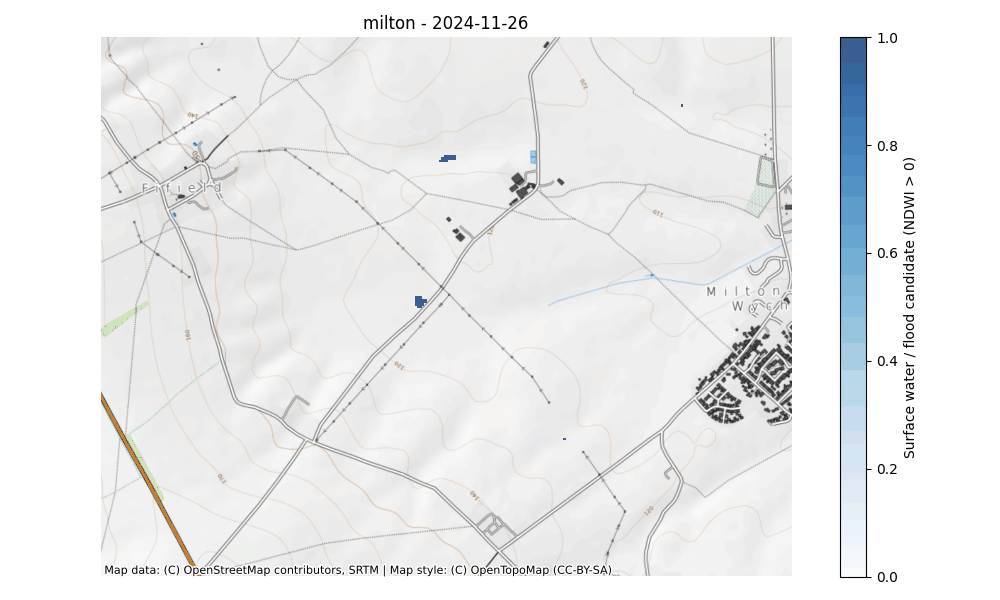

In [63]:
# out_nc = (
#     "/Users/vm/Desktop/dir.tmp/spongeworks/eo_data/milton/"
#     "flood_mask_udp/2021/milton_flood_mask_udp_2021.nc"
# )

gif_path = Path(out_nc).with_suffix(".gif")

with xr.open_dataset(out_nc, decode_coords="all") as plot_ds:
    plot_variable = next(
        name for name in plot_ds.data_vars
        if plot_ds[name].ndim >= 2 and name != "crs"
    )
    plot_data = plot_ds[plot_variable].load()

for band_axis in ("band", "bands"):
    if band_axis in plot_data.dims:
        plot_data = plot_data.isel({band_axis: 0}, drop=True)

raster_crs = plot_data.rio.crs
if raster_crs is None:
    raise ValueError(
        "The NetCDF has no readable CRS. Assign its known source CRS "
        "with plot_data.rio.write_crs(...) before adding the basemap."
    )

time_axis = next(dim for dim in ("t", "time") if dim in plot_data.dims)
plot_data = plot_data.sortby(time_axis)

if plot_data.sizes[time_axis] == 0:
    raise ValueError("The dataset contains no time steps to animate.")


def water_mask_at(frame_index):
    frame = plot_data.isel({time_axis: frame_index}).transpose("y", "x")
    return (frame > 0).where(frame.notnull() & (frame > 0))


frame_fig, frame_ax = plt.subplots(figsize=(10, 6))

try:
    water_layer = water_mask_at(0).plot.pcolormesh(
        ax=frame_ax,
        x="x",
        y="y",
        cmap="Blues",
        vmin=0,
        vmax=1,
        alpha=0.80,
        zorder=2,
        cbar_kwargs={"label": "Surface water / flood candidate (NDWI > 0)"},
    )

    ctx.add_basemap(
        frame_ax,
        source=ctx.providers.OpenTopoMap,
        crs=raster_crs,
        zorder=0,
    )

    frame_ax.set_aspect("equal")
    frame_ax.set_axis_off()
    title = frame_ax.set_title(f"{site_name} - 0000-00-00")
    frame_fig.tight_layout()

    writer = PillowWriter(fps=2)

    with writer.saving(frame_fig, str(gif_path), dpi=100):
        for frame_index in range(plot_data.sizes[time_axis]):
            timestamp = pd.Timestamp(
                plot_data[time_axis].isel({time_axis: frame_index}).values
            )

            water_layer.set_array(water_mask_at(frame_index).values.ravel())
            title.set_text(f"{site_name} - {timestamp:%Y-%m-%d}")
            writer.grab_frame()
finally:
    plt.close(frame_fig)

print(f"Saved GIF: {gif_path}")
display(Image(filename=str(gif_path)))

# SAR fixed Threshold 
----

## Method / UPD 

This workflow creates a Sentinel-1 flood-candidate mask from VH backscatter:

1. Loads Sentinel-1 GRD VH data for the selected area and dates.
2. Applies the `sigma0-ellipsoid` backscatter correction using the Copernicus 30 m elevation model.
3. Converts positive VH values to decibels.
4. Classifies pixels < the configurable threshold of **−22.2 dB** as flood candidates (`1`); other valid pixels are classified as non-flood (`0`). Invalid or missing values remain no-data.

This is a simple threshold-based indicator, not a validated flood extent: it includes permanent water and may require threshold tuning and additional masking for a specific site.

For related context, see the [referenced article](https://www.sciencedirect.com/science/article/pii/S0034425726000969?via%3Dihub).

In [65]:
"""Flood mask UDP based on the working NDWI UDP pattern."""

import json
import os
import xarray as xr
from openeo.api.process import Parameter


UDP_ID = "flood_mask_s1_vh_v2"
VV_WATER_THRESH = -13.4
VH_WATER_THRESH = -22.2
wait_for_completion = False

output_dir = os.path.join(
    "/Users/vm/Desktop/dir.tmp/spongeworks/eo_data",
    site_name,
    "SAR_fixed_threshold_udp",
)
os.makedirs(output_dir, exist_ok=True)

temporal_extent_param = Parameter(
    name="temporal_extent",
    description="Start and end dates for the Sentinel-1 GRD query.",
    schema={"type": "array", "subtype": "temporal-interval"},
)
spatial_extent_param = Parameter(
    name="spatial_extent",
    description="Bounding box in EPSG:4326: west, south, east, north, crs.",
    schema={"type": "object", "subtype": "geojson"},
)
vv_threshold_param = Parameter(
    name="vv_threshold_db",
    description="Flood candidates have VV strictly below this threshold in dB.",
    schema={"type": "number"},
)
vh_threshold_param = Parameter(
    name="vh_threshold_db",
    description="Flood candidates have VH strictly below this threshold in dB.",
    schema={"type": "number"},
)
udp_parameters = [
    temporal_extent_param, spatial_extent_param,
    vv_threshold_param, vh_threshold_param,
]

s1_cube = connection.load_collection(
    collection_id="SENTINEL1_GRD",
    spatial_extent=spatial_extent_param,
    temporal_extent=temporal_extent_param,
    bands=["VV", "VH"],
)
s1_scatter = s1_cube.sar_backscatter(
    coefficient="sigma0-ellipsoid",
    elevation_model="COPERNICUS_30",
)

vv_linear = s1_scatter.band("VV")
vh_linear = s1_scatter.band("VH")
# Non-positive values cannot be converted to dB; mask them to no-data.
vv_valid = vv_linear.mask(vv_linear <= 0)
vh_valid = vh_linear.mask(vh_linear <= 0)
vv_db = 10 * (vv_valid.ln() / 2.302585092994046)
vh_db = 10 * (vh_valid.ln() / 2.302585092994046)

# Boolean comparison gives 1/0 flags; no-data propagates.
flood_mask = (
    vv_db.apply(lambda x: x < vv_threshold_param)
    & vh_db.apply(lambda x: x < vh_threshold_param)
)

flood_udp_graph = flood_mask.add_dimension(
    name="bands",
    label="flood_mask",
    type="bands",
)

udp_metadata = {
    "id": UDP_ID,
    "summary": "Sentinel-1 VV and VH threshold flood mask",
    "description": (
        "Loads Sentinel-1 GRD VV and VH, computes sigma0-ellipsoid backscatter "
        "(COPERNICUS_30), converts positive VV and VH to dB and returns one "
        "flood_mask band: 1 where VV < vv_threshold_db AND VH < vh_threshold_db, "
        "otherwise 0. Missing or non-positive input is no-data. "
        "Includes permanent water."
    ),
    "parameters": [p.to_dict() for p in udp_parameters],
    "process_graph": flood_udp_graph.flat_graph(),
}

json.dumps(udp_metadata, allow_nan=False)
udp_debug_json = os.path.join(output_dir, f"{UDP_ID}_process_graph.json")
with open(udp_debug_json, "w", encoding="utf-8") as file:
    json.dump(udp_metadata, file, indent=2, allow_nan=False)

connection.save_user_defined_process(
    user_defined_process_id=UDP_ID,
    process_graph=flood_udp_graph,
    parameters=udp_parameters,
    summary=udp_metadata["summary"],
    description=udp_metadata["description"],
)
print(f"UDP saved/updated: {UDP_ID}")


def ensure_flood_mask_datavar(nc_file):
    """Normalize the backend's single raster output to variable `flood_mask`."""
    with xr.open_dataset(nc_file, engine="netcdf4") as ds:
        local = ds.load()

    if "flood_mask" in local.data_vars:
        final = local
    else:
        raster_variables = [
            name for name, da in local.data_vars.items() if da.ndim >= 2
        ]
        if len(raster_variables) != 1:
            raise ValueError(
                f"Expected one raster in {nc_file}; found {raster_variables}"
            )
        final = local.rename({raster_variables[0]: "flood_mask"})

    da = final["flood_mask"]
    for band_dim in ("bands", "band"):
        if band_dim in da.dims:
            if da.sizes[band_dim] != 1:
                raise ValueError(f"Expected one output band in {nc_file}.")
            da = da.isel({band_dim: 0}, drop=True)

    da.attrs.update(
        long_name="Sentinel-1 VV and VH threshold flood mask",
        units="1",
        vv_threshold_db=VV_WATER_THRESH,
        vh_threshold_db=VH_WATER_THRESH,
        threshold_combination="AND",
        description="1 = flood candidate; 0 = non-flood; missing = no-data",
    )
    final["flood_mask"] = da
    temporary_file = nc_file + ".tmp"
    final.to_netcdf(temporary_file, engine="netcdf4")
    os.replace(temporary_file, nc_file)


submitted_flood_jobs = []
for year in range(startYear, endYear + 1):
    if year < 2017:
        continue

    year_start = max(f"{year}-01-01", poi[0])
    year_end = min(f"{year}-12-31", poi[1])
    if year_start > year_end:
        continue

    year_dir = os.path.join(output_dir, str(year))
    os.makedirs(year_dir, exist_ok=True)
    out_nc = os.path.join(year_dir, f"{site_name}_SAR_fixedthreshold_udp_{year}.nc")

    result_cube = connection.datacube_from_process(
        process_id=UDP_ID,
        temporal_extent=[year_start, year_end],
        spatial_extent={
            "west": float(W), "south": float(S),
            "east": float(E), "north": float(N),
            "crs": "EPSG:4326",
        },
        vv_threshold_db=VV_WATER_THRESH,
        vh_threshold_db=VH_WATER_THRESH,
    )
    
    job = result_cube.create_job(
        title=f"S1_FloodMask_UDP_{site_name}_{year}",
        description=(
            f"VV < {VV_WATER_THRESH} dB AND VH < {VH_WATER_THRESH} dB: "
            f"{site_name}, {year}."
        ),
        out_format="NetCDF",
    )
    submitted_flood_jobs.append(
        {"year": year, "out_nc": out_nc, "job": job}
    )
    print(f"Created job for {year}: job_id={job.job_id}")

    if wait_for_completion:
        job.start_and_wait()
        job.get_results().download_file(out_nc)
        ensure_flood_mask_datavar(out_nc)
        print(f"{year}: saved flood-mask timeseries to {out_nc}")
    else:
        job.start_job()
        print(f"{year}: started job_id={job.job_id}")

print(f"Submitted {len(submitted_flood_jobs)} annual flood-mask job(s).")


Preflight process graph validation raised: [UpstreamValidationInfo] Backend 'cdse' reported validation errors [ProcessParameterRequired] Process 'n/a' parameter 'spatial_extent' is required.
Preflight process graph validation raised: [UpstreamValidationInfo] Backend 'cdse' reported validation errors [ProcessUnsupported] Process with identifier 'flood_mask_s1_vh_v2' is not available in namespace 'None'.


UDP saved/updated: flood_mask_s1_vh_v2
Created job for 2024: job_id=cdse-j-261023135438491b9204ddaf6aed2b6b
2024: started job_id=cdse-j-261023135438491b9204ddaf6aed2b6b
Submitted 1 annual flood-mask job(s).


In [66]:
job = submitted_flood_jobs[0]["job"]
out_nc = submitted_flood_jobs[0]["out_nc"]
try:
    job.start_and_wait()
    job.get_results().download_file(out_nc)
    ensure_flood_mask_datavar(out_nc)
    print("Saved", out_nc)
except Exception as e:
    print("Job failed:", e)
    for log in job.logs(level="error"):
        print("---", log.get("message", "")[:3000])

0:00:00 Job 'cdse-j-261023135438491b9204ddaf6aed2b6b': send 'start'
0:00:00 Job 'cdse-j-261023135438491b9204ddaf6aed2b6b': created (progress 0%)
0:00:05 Job 'cdse-j-261023135438491b9204ddaf6aed2b6b': queued (progress 0%)
0:00:11 Job 'cdse-j-261023135438491b9204ddaf6aed2b6b': queued (progress 0%)
0:00:19 Job 'cdse-j-261023135438491b9204ddaf6aed2b6b': queued (progress 0%)
0:00:29 Job 'cdse-j-261023135438491b9204ddaf6aed2b6b': queued (progress 0%)
0:00:42 Job 'cdse-j-261023135438491b9204ddaf6aed2b6b': running (progress N/A)
0:00:57 Job 'cdse-j-261023135438491b9204ddaf6aed2b6b': running (progress N/A)
0:01:16 Job 'cdse-j-261023135438491b9204ddaf6aed2b6b': running (progress N/A)
0:01:41 Job 'cdse-j-261023135438491b9204ddaf6aed2b6b': finished (progress 100%)
Saved /Users/vm/Desktop/dir.tmp/spongeworks/eo_data/milton/SAR_fixed_threshold_udp/2024/milton_SAR_fixedthreshold_udp_2024.nc


In [67]:
# connection.job("cdse-j-26100713370245cdbb9a2aea4e59e736").stop()
# print(connection.job("cdse-j-26100713370245cdbb9a2aea4e59e736").status())  # → "canceled"

## Plot results - GIF 

Saved GIF: /Users/vm/Desktop/dir.tmp/spongeworks/eo_data/milton/SAR_fixed_threshold_udp/2024/milton_SAR_fixedthreshold_udp_2024.gif


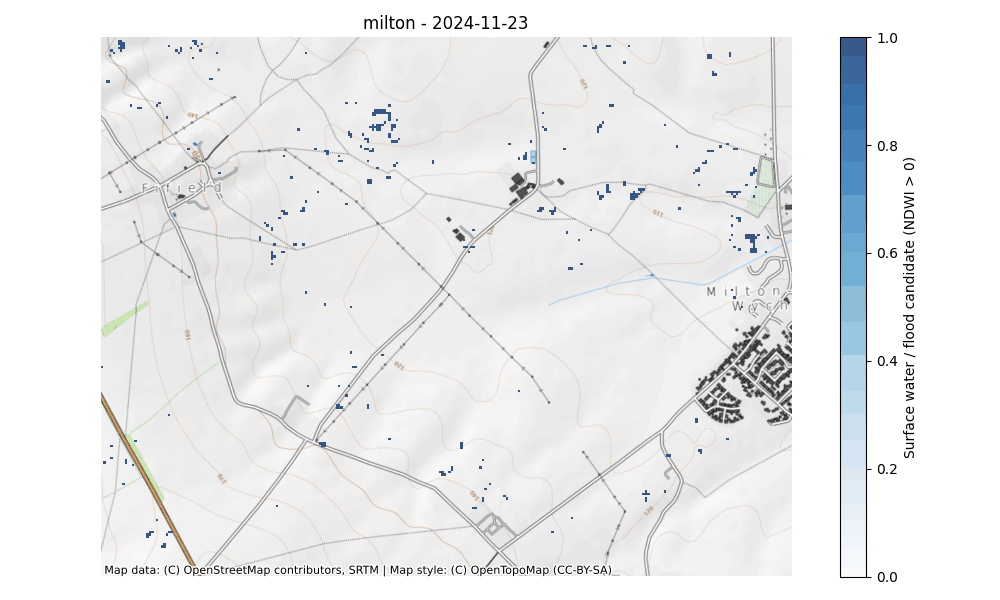

In [68]:
gif_path = Path(out_nc).with_suffix(".gif")

with xr.open_dataset(out_nc, decode_coords="all") as plot_ds:
    plot_variable = next(
        name for name in plot_ds.data_vars
        if plot_ds[name].ndim >= 2 and name != "crs"
    )
    plot_data = plot_ds[plot_variable].load()

for band_axis in ("band", "bands"):
    if band_axis in plot_data.dims:
        plot_data = plot_data.isel({band_axis: 0}, drop=True)

raster_crs = plot_data.rio.crs
if raster_crs is None:
    raise ValueError(
        "The NetCDF has no readable CRS. Assign its known source CRS "
        "with plot_data.rio.write_crs(...) before adding the basemap."
    )

time_axis = next(dim for dim in ("t", "time") if dim in plot_data.dims)
plot_data = plot_data.sortby(time_axis)

if plot_data.sizes[time_axis] == 0:
    raise ValueError("The dataset contains no time steps to animate.")


def water_mask_at(frame_index):
    frame = plot_data.isel({time_axis: frame_index}).transpose("y", "x")
    return (frame > 0).where(frame.notnull() & (frame > 0))


frame_fig, frame_ax = plt.subplots(figsize=(10, 6))

try:
    water_layer = water_mask_at(0).plot.pcolormesh(
        ax=frame_ax,
        x="x",
        y="y",
        cmap="Blues",
        vmin=0,
        vmax=1,
        alpha=0.80,
        zorder=2,
        cbar_kwargs={"label": "Surface water / flood candidate (NDWI > 0)"},
    )

    ctx.add_basemap(
        frame_ax,
        source=ctx.providers.OpenTopoMap,
        crs=raster_crs,
        zorder=0,
    )

    frame_ax.set_aspect("equal")
    frame_ax.set_axis_off()
    title = frame_ax.set_title(f"{site_name} - 0000-00-00")
    frame_fig.tight_layout()

    writer = PillowWriter(fps=2)

    with writer.saving(frame_fig, str(gif_path), dpi=100):
        for frame_index in range(plot_data.sizes[time_axis]):
            timestamp = pd.Timestamp(
                plot_data[time_axis].isel({time_axis: frame_index}).values
            )

            water_layer.set_array(water_mask_at(frame_index).values.ravel())
            title.set_text(f"{site_name} - {timestamp:%Y-%m-%d}")
            writer.grab_frame()
finally:
    plt.close(frame_fig)

print(f"Saved GIF: {gif_path}")
display(Image(filename=str(gif_path)))

# SAR local threshold 
---- 

## Method / UPD 

Use 3 years of data to find local / pixel thresholds (i.e. 5th percentile) for VV and VH instead of using fixed threshold(s). The method treats the lower-backscatter mode as water, so lower VV or VH backscatter can indicate a greater likelihood of surface wate



In [69]:
"""Flood candidates below per-pixel seasonal VV and VH fifth percentiles."""

import json
import calendar
from datetime import date, timedelta
import os
import xarray as xr
from openeo import UDF
from openeo.api.process import Parameter


UDP_ID = "flood_mask_s1_seasonal_p05_v1"
wait_for_completion = False
# History assembly happens before the UDF and also needs Python memory.
seasonal_job_options = {
    "executor-memoryOverhead": "4G",
    "python-memory": "3G",
    "executor-cores": 1,
    "task-cpus": 1,
}

output_dir = os.path.join(
    "/Users/vm/Desktop/dir.tmp/spongeworks/eo_data",
    site_name,
    "SAR_local_threshold_udp",
)
os.makedirs(output_dir, exist_ok=True)

# apply_dimension on t supplies the full history, even for spatially tiled UDFs.
seasonal_threshold_udf = '''
import calendar
from datetime import date, timedelta
import numpy as np
from openeo.udf import XarrayDataCube


def apply_datacube(cube: XarrayDataCube, context: dict) -> XarrayDataCube:
    array = cube.get_array()
    ordered = array.transpose("t", ...)
    values = np.asarray(ordered.values, dtype=np.float32)
    days = ordered.coords["t"].values.astype("datetime64[D]")
    start, end = [np.datetime64(value, "D") for value in context["target_extent"]]
    thresholds = np.full(values.shape, np.nan, dtype=np.float32)

    for index in np.flatnonzero((days >= start) & (days < end)):
        target = date.fromisoformat(str(days[index]))
        baseline = np.zeros(days.shape, dtype=bool)
        for offset in (1, 2, 3):
            year = target.year - offset
            # Match February 29 to February 28 in non-leap reference years.
            day = min(target.day, calendar.monthrange(year, target.month)[1])
            center = date(year, target.month, day)
            lower = np.datetime64(center - timedelta(days=3), "D")
            upper = np.datetime64(center + timedelta(days=3), "D")
            baseline |= (days >= lower) & (days <= upper)

        if not baseline.any():
            continue
        samples = values[baseline].reshape(int(baseline.sum()), -1)
        samples[~np.isfinite(samples)] = np.nan
        usable = np.isfinite(samples).any(axis=0)
        if usable.any():
            thresholds[index].reshape(-1)[usable] = np.nanquantile(
                samples[:, usable], 0.05, axis=0, method="linear"
            )

    result = ordered.copy(data=thresholds).transpose(*array.dims)
    return XarrayDataCube(result)
'''

temporal_extent_param = Parameter(
    name="temporal_extent",
    description="Target observation interval, inclusive start and exclusive end.",
    schema={"type": "array", "subtype": "temporal-interval"},
)
reference_extent_param = Parameter(
    name="reference_temporal_extent",
    description=(
        "Load interval covering the target interval and the preceding three "
        "calendar years, extended by three days before the earliest reference date."
    ),
    schema={"type": "array", "subtype": "temporal-interval"},
)
spatial_extent_param = Parameter(
    name="spatial_extent",
    description="Bounding box in EPSG:4326: west, south, east, north, crs.",
    schema={"type": "object", "subtype": "geojson"},
)
udp_parameters = [
    temporal_extent_param, reference_extent_param, spatial_extent_param,
]

s1_cube = connection.load_collection(
    collection_id="SENTINEL1_GRD",
    spatial_extent=spatial_extent_param,
    temporal_extent=reference_extent_param,
    bands=["VV", "VH"],
)
s1_scatter = s1_cube.sar_backscatter(
    coefficient="sigma0-ellipsoid",
    elevation_model="COPERNICUS_30",
)

# Non-positive values cannot be converted to dB; mask them to no-data.
s1_valid = s1_scatter.mask(s1_scatter <= 0)
s1_db = 10 * (s1_valid.ln() / 2.302585092994046)
seasonal_thresholds = s1_db.apply_dimension(
    dimension="t",
    process=UDF(
        code=seasonal_threshold_udf,
        runtime="Python",
        context={"from_parameter": "context"},
    ),
    context={"target_extent": temporal_extent_param},
).filter_temporal(extent=temporal_extent_param)
target_db = s1_db.filter_temporal(extent=temporal_extent_param)

# CDSE supports subtraction, but not lt, as a merge_cubes resolver.
difference_db = target_db - seasonal_thresholds
below_threshold = difference_db.apply(lambda value: value < 0)
flood_mask = below_threshold.band("VV") & below_threshold.band("VH")
# Explicitly preserve no-data even if the other polarization is not flooded.
missing = (
    target_db.apply("is_nodata") | seasonal_thresholds.apply("is_nodata")
)
flood_mask = flood_mask.mask(missing.band("VV") | missing.band("VH"))

flood_udp_graph = flood_mask.add_dimension(
    name="bands",
    label="flood_mask",
    type="bands",
)

udp_metadata = {
    "id": UDP_ID,
    "summary": "Sentinel-1 seasonal fifth-percentile VV and VH flood mask",
    "description": (
        "Computes sigma0-ellipsoid backscatter (COPERNICUS_30) in dB. For each "
        "target date, pixel and polarization, pools valid observations within "
        "+/-3 calendar days of the matching date in each of the preceding three "
        "years and estimates the fifth percentile using linear interpolation. "
        "February 29 maps to February 28 in non-leap reference years. Returns "
        "flood_mask: 1 where VV AND VH are strictly below their respective "
        "percentiles, otherwise 0. Missing/non-positive observations or no valid "
        "baseline for either polarization give no-data. Any available valid "
        "baseline samples are used; a full three years of coverage is not required. "
        "This is a low-backscatter anomaly candidate, not confirmed flooding."
    ),
    "parameters": [p.to_dict() for p in udp_parameters],
    "process_graph": flood_udp_graph.flat_graph(),
}

json.dumps(udp_metadata, allow_nan=False)
udp_debug_json = os.path.join(output_dir, f"{UDP_ID}_process_graph.json")
with open(udp_debug_json, "w", encoding="utf-8") as file:
    json.dump(udp_metadata, file, indent=2, allow_nan=False)

connection.save_user_defined_process(
    user_defined_process_id=UDP_ID,
    process_graph=flood_udp_graph,
    parameters=udp_parameters,
    summary=udp_metadata["summary"],
    description=udp_metadata["description"],
)
print(f"UDP saved/updated: {UDP_ID}")


def ensure_seasonal_flood_mask_datavar(nc_file, reference_extent):
    """Normalize the backend's single raster output to variable `flood_mask`."""
    with xr.open_dataset(nc_file, engine="netcdf4") as ds:
        local = ds.load()

    if "flood_mask" in local.data_vars:
        final = local
    else:
        raster_variables = [
            name for name, da in local.data_vars.items() if da.ndim >= 2
        ]
        if len(raster_variables) != 1:
            raise ValueError(
                f"Expected one raster in {nc_file}; found {raster_variables}"
            )
        final = local.rename({raster_variables[0]: "flood_mask"})

    da = final["flood_mask"]
    for band_dim in ("bands", "band"):
        if band_dim in da.dims:
            if da.sizes[band_dim] != 1:
                raise ValueError(f"Expected one output band in {nc_file}.")
            da = da.isel({band_dim: 0}, drop=True)

    da.attrs.update(
        long_name="Sentinel-1 seasonal fifth-percentile VV and VH flood mask",
        units="1",
        threshold_percentile=5,
        reference_years=10,
        reference_half_window_days=3,
        reference_temporal_start=reference_extent[0],
        reference_temporal_end=reference_extent[1],
        threshold_combination="AND",
        threshold_method="Per-pixel and polarization; pooled samples; linear quantile",
        leap_day_policy="February 29 maps to February 28 in non-leap years",
        baseline_coverage="Use available valid samples; none gives no-data",
        description="1 = flood candidate; 0 = non-flood; missing = no-data",
    )
    final["flood_mask"] = da
    temporary_file = nc_file + ".tmp"
    final.to_netcdf(temporary_file, engine="netcdf4")
    os.replace(temporary_file, nc_file)


submitted_flood_jobs = []
for year in range(startYear, endYear + 1):
    if year < 2017:
        continue

    year_start = max(f"{year}-01-01", poi[0])
    year_end = min(f"{year + 1}-01-01", poi[1])
    if year_start >= year_end:
        continue

    first_date = date.fromisoformat(year_start)
    reference_year = first_date.year - 3
    reference_day = min(
        first_date.day, calendar.monthrange(reference_year, first_date.month)[1]
    )
    reference_start = date(reference_year, first_date.month, reference_day) - timedelta(days=3)
    reference_extent = [reference_start.isoformat(), year_end]

    year_dir = os.path.join(output_dir, str(year))
    os.makedirs(year_dir, exist_ok=True)
    out_nc = os.path.join(year_dir, f"{site_name}_SAR_local_threshold_udp_{year}.nc")

    result_cube = connection.datacube_from_process(
        process_id=UDP_ID,
        temporal_extent=[year_start, year_end],
        spatial_extent={
            "west": float(W), "south": float(S),
            "east": float(E), "north": float(N),
            "crs": "EPSG:4326",
        },
        reference_temporal_extent=reference_extent,
    )
    
    job = result_cube.create_job(
        title=f"S1_SeasonalP05_FloodMask_UDP_{site_name}_{year}",
        description=(
            f"VV AND VH below per-pixel seasonal fifth percentiles from the "
            f"previous 3 years (+/-3 days): {site_name}, {year}."
        ),
        out_format="NetCDF",
        job_options=seasonal_job_options,
    )
    submitted_flood_jobs.append(
        {"year": year, "out_nc": out_nc, "reference_extent": reference_extent, "job": job}
    )
    print(f"Created job for {year}: job_id={job.job_id}")

    if wait_for_completion:
        job.start_and_wait()
        job.get_results().download_file(out_nc)
        ensure_seasonal_flood_mask_datavar(out_nc, reference_extent)
        print(f"{year}: saved flood-mask timeseries to {out_nc}")
    else:
        job.start_job()
        print(f"{year}: started job_id={job.job_id}")

print(f"Submitted {len(submitted_flood_jobs)} annual flood-mask job(s).")


Preflight process graph validation raised: [UpstreamValidationInfo] Backend 'cdse' reported validation errors [ProcessParameterRequired] Process 'n/a' parameter 'spatial_extent' is required.


UDP saved/updated: flood_mask_s1_seasonal_p05_v1


Preflight process graph validation raised: [UpstreamValidationInfo] Backend 'cdse' reported validation errors [ProcessUnsupported] Process with identifier 'flood_mask_s1_seasonal_p05_v1' is not available in namespace 'None'.


Created job for 2024: job_id=cdse-j-26102314164448f489a8ac1a270e8c30
2024: started job_id=cdse-j-26102314164448f489a8ac1a270e8c30
Submitted 1 annual flood-mask job(s).


In [70]:
job = submitted_flood_jobs[0]["job"]
out_nc = submitted_flood_jobs[0]["out_nc"]
try:
    job.start_and_wait()
    job.get_results().download_file(out_nc)
    ensure_seasonal_flood_mask_datavar(
        out_nc, submitted_flood_jobs[0]["reference_extent"]
    )
    print("Saved", out_nc)
except Exception as e:
    print("Job failed:", e)
    for log in job.logs(level="error"):
        print("---", log.get("message", "")[:3000])

0:00:00 Job 'cdse-j-26102314164448f489a8ac1a270e8c30': send 'start'
0:00:01 Job 'cdse-j-26102314164448f489a8ac1a270e8c30': created (progress 0%)
0:00:07 Job 'cdse-j-26102314164448f489a8ac1a270e8c30': queued (progress 0%)
0:00:13 Job 'cdse-j-26102314164448f489a8ac1a270e8c30': queued (progress 0%)
0:00:21 Job 'cdse-j-26102314164448f489a8ac1a270e8c30': queued (progress 0%)
0:00:32 Job 'cdse-j-26102314164448f489a8ac1a270e8c30': running (progress N/A)
0:00:45 Job 'cdse-j-26102314164448f489a8ac1a270e8c30': running (progress N/A)
0:01:01 Job 'cdse-j-26102314164448f489a8ac1a270e8c30': running (progress N/A)
0:01:20 Job 'cdse-j-26102314164448f489a8ac1a270e8c30': running (progress N/A)
0:01:44 Job 'cdse-j-26102314164448f489a8ac1a270e8c30': running (progress N/A)
0:02:14 Job 'cdse-j-26102314164448f489a8ac1a270e8c30': running (progress N/A)
0:02:51 Job 'cdse-j-26102314164448f489a8ac1a270e8c30': running (progress N/A)
0:03:38 Job 'cdse-j-26102314164448f489a8ac1a270e8c30': running (progress N/A)
0:0

## Plot results GIF 

Saved GIF: /Users/vm/Desktop/dir.tmp/spongeworks/eo_data/milton/SAR_local_threshold_udp/2024/milton_SAR_local_threshold_udp_2024.gif


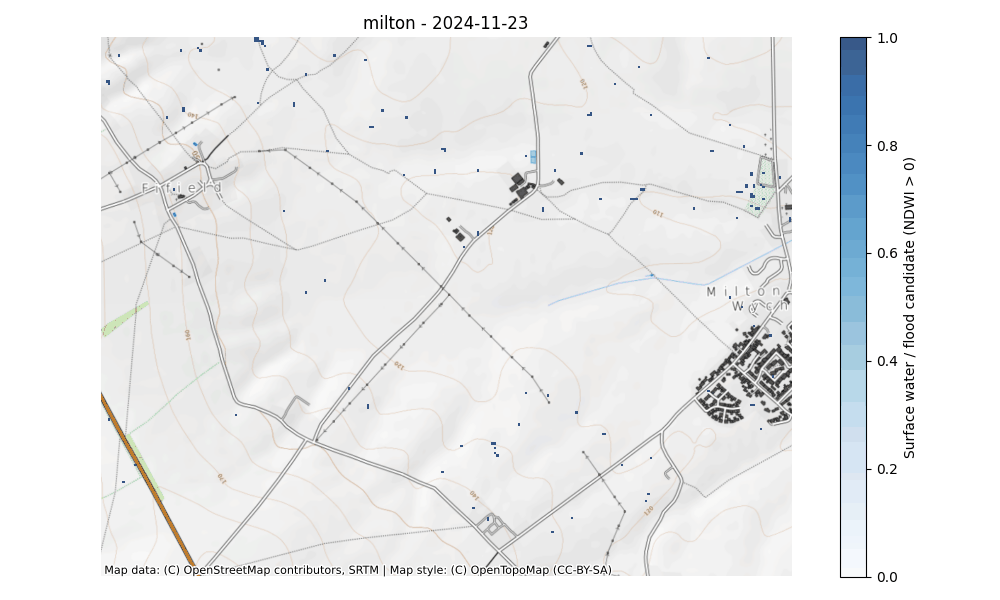

In [71]:
gif_path = Path(out_nc).with_suffix(".gif")

with xr.open_dataset(out_nc, decode_coords="all") as plot_ds:
    plot_variable = next(
        name for name in plot_ds.data_vars
        if plot_ds[name].ndim >= 2 and name != "crs"
    )
    plot_data = plot_ds[plot_variable].load()

for band_axis in ("band", "bands"):
    if band_axis in plot_data.dims:
        plot_data = plot_data.isel({band_axis: 0}, drop=True)

raster_crs = plot_data.rio.crs
if raster_crs is None:
    raise ValueError(
        "The NetCDF has no readable CRS. Assign its known source CRS "
        "with plot_data.rio.write_crs(...) before adding the basemap."
    )

time_axis = next(dim for dim in ("t", "time") if dim in plot_data.dims)
plot_data = plot_data.sortby(time_axis)

if plot_data.sizes[time_axis] == 0:
    raise ValueError("The dataset contains no time steps to animate.")


def water_mask_at(frame_index):
    frame = plot_data.isel({time_axis: frame_index}).transpose("y", "x")
    return (frame > 0).where(frame.notnull() & (frame > 0))


frame_fig, frame_ax = plt.subplots(figsize=(10, 6))

try:
    water_layer = water_mask_at(0).plot.pcolormesh(
        ax=frame_ax,
        x="x",
        y="y",
        cmap="Blues",
        vmin=0,
        vmax=1,
        alpha=0.80,
        zorder=2,
        cbar_kwargs={"label": "Surface water / flood candidate (NDWI > 0)"},
    )

    ctx.add_basemap(
        frame_ax,
        source=ctx.providers.OpenTopoMap,
        crs=raster_crs,
        zorder=0,
    )

    frame_ax.set_aspect("equal")
    frame_ax.set_axis_off()
    title = frame_ax.set_title(f"{site_name} - 0000-00-00")
    frame_fig.tight_layout()

    writer = PillowWriter(fps=2)

    with writer.saving(frame_fig, str(gif_path), dpi=100):
        for frame_index in range(plot_data.sizes[time_axis]):
            timestamp = pd.Timestamp(
                plot_data[time_axis].isel({time_axis: frame_index}).values
            )

            water_layer.set_array(water_mask_at(frame_index).values.ravel())
            title.set_text(f"{site_name} - {timestamp:%Y-%m-%d}")
            writer.grab_frame()
finally:
    plt.close(frame_fig)

print(f"Saved GIF: {gif_path}")
display(Image(filename=str(gif_path)))